In [23]:
import requests
import json
import os
import sys
sys.path.append("../src")

from config import FREECRYPTO_TOKEN,NEWS_API_KEY,GROQ_API_KEY
from langchain_core.tools import tool
from newsapi import NewsApiClient
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage,HumanMessage
from langgraph.graph import START,END,StateGraph
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.checkpoint.memory import MemorySaver

In [24]:
llm = ChatGroq(model="openai/gpt-oss-120b",api_key=GROQ_API_KEY)

In [25]:
@tool
def crypto_list_tool(limit:int=25)-> str:
    """
    Fetches a list of available cryptocurrencies (symbol + name) from FreeCryptoAPI.
    Args:
        limit (int): Max number of coins to return (to keep responses compact).
    Returns:
        str: JSON string with condensed list: [{"symbol": "...","name":"..."},...]
    """

    url = "https://api.freecryptoapi.com/v1/getCryptoList"
    headers = {"Authorization":f"Bearer {FREECRYPTO_TOKEN}"}
    resp = requests.get(url,headers=headers,timeout=30)
    try:
        data = resp.json()
    except Exception:
        return json.dumps({"status":False,"error":"Invalid JSON from API"})
    
    if isinstance(data,list):
        slim = []
        for item in data[:max(1,limit)]:
            sym = item.get("symbol") or item.get("symbol") or item.get("ticker")
            nm = item.get("name") or item.get("Name")
            if sym or nm:
                slim.append({"symbol":sym,"name":nm})
        return json.dumps({"status":True,"coins":slim},indent=2)
    return json.dumps(data,indent=2)

In [4]:
#crypto data tool for one Cryptocurrency :fetch detialed data for a single symbol
#@tool 
#def crypto_data_tool(symbol) -> str :
 #   """
   # Fetches detailed data for a given crypto symbol (e.g.,BTC) from FreeCryptoAPI.
#Args:
 #       - symbol (str): Ticker symbol like 'BTC','ETH', etc.
  #  Returns:
  #  str: Json string ot the API response.
   # """
    #url="https://api.freecryptoapi.com/v1/getData"
    #headers = {"Authorization":f"Bearer {FREECRYPTO_TOKEN}"}
    #params = {"symbol":symbol.upper().strip()}
    #resp = requests.get(url,headers=headers,params=params)

    #try:
     #   data = resp.json()
    #except Exception:
     #   return json.dumps({"status":False,"error":"Invalid JSON from API"})

    #return json.dumps(data,indent=2)



In [26]:
@tool
def crypto_data_tool(symbol: str) -> str:
    """
    Fetches detailed market data for a crypto ticker symbol from FreeCryptoAPI.
    Args:
        symbol (str): Ticker symbol as text, e.g. 'BTC' or 'ETH'. Never a number.
    Returns:
        str: JSON string of the API response.
    """
    symbol = str(symbol).strip().upper()
    if not symbol.isalpha():
        return json.dumps({
            "status": False,
            "error": f"Invalid symbol {symbol!r}. Use a ticker such as BTC or ETH."
        })

    url = "https://api.freecryptoapi.com/v1/getData"
    headers = {"Authorization": f"Bearer {FREECRYPTO_TOKEN}"}

    try:
        resp = requests.get(url, headers=headers, params={"symbol": symbol}, timeout=15)
        resp.raise_for_status()
        data = resp.json()
    except requests.exceptions.RequestException as e:
        return json.dumps({"status": False, "error": f"Request failed: {e}"})
    except ValueError:
        return json.dumps({"status": False, "error": "Invalid JSON from API"})

    return json.dumps(data, indent=2)

In [6]:
#crypto news via News api
#@tool
#def crypto_news_tool(query:str="crypto",mode:str="top",max_items:int=5)->str:
#    """
 #   Fetches recent/important news using NewsApi and returns a condensed list.
  #  Args:
   #     - query(str): Search query, eg 'bitcoin',''ethereum','crypto regulation'
    #    - max items (int): Max number of articles to return (default: 5)
    #Returns:
     #   str: Json string with fields : title, source , url,publishedAt
    #"""

    #newsapi = NewsApiClient(api_key=NEWS_API_KEY)

    #try: 
     #   res = newsapi.get_everything(
      #      q = query,
       #     language = "en",
        #    sort_by="publishedAt",
         #   page=1
        #)
    #except Exception as e:
     #   return json.dumps({"status":False,"error":str(e)})
    
    #slim: List[Dict[str,Any]] =[]
    #for a in articles[:max(1,max_items)]:
     #   slim.append({
      #      "title":a.get("title"),
       #     "source":(a.get("source") or {}).get("name"),
        #    "url": a.get("publishedAt"),
         #   "description": a.get("description"),
          #  "content": a.get("content")
        #})

    #return json.dumps(
     #   {
      #      "status":True,
       #     "totalResults":len(articles),
        #    "returned":len(slim),
         #   "articles":slim,
        #},
        #indent=2
#    )

In [27]:
@tool
def crypto_news_tool(query: str = "crypto", max_items: int = 5) -> str:
    """
    Fetches recent news using NewsAPI and returns a condensed list.
    Args:
        query (str): Search query, e.g. 'bitcoin', 'ethereum', 'crypto regulation'
        max_items (int): Max number of articles to return (default: 5)
    Returns:
        str: JSON string with fields: title, source, url, publishedAt, description
    """
    newsapi = NewsApiClient(api_key=NEWS_API_KEY)

    try:
        res = newsapi.get_everything(
            q=query,
            language="en",
            sort_by="publishedAt",
            page=1,
            page_size=max(1, max_items),
        )
    except Exception as e:
        return json.dumps({"status": False, "error": str(e)})

    articles = res.get("articles", [])

    slim: List[Dict[str, Any]] = []
    for a in articles[:max(1, max_items)]:
        slim.append({
            "title": a.get("title"),
            "source": (a.get("source") or {}).get("name"),
            "url": a.get("url"),
            "publishedAt": a.get("publishedAt"),
            "description": a.get("description"),
        })

    return json.dumps(
        {
            "status": True,
            "totalResults": res.get("totalResults", len(articles)),
            "returned": len(slim),
            "articles": slim,
        },
        indent=2,
    )

In [28]:
#list conatinign tool functions
tools = [crypto_list_tool,crypto_data_tool,crypto_news_tool]

In [29]:
#ToolNode
tool_node = ToolNode(tools=tools)

In [30]:
#bind tools to llm
llm_with_tools = llm.bind_tools(tools)

In [31]:
#writing system prompt(agent personality + Rules)
sys_msg = SystemMessage(
    content="""
    You are a professional Crypto Market Analyst Agent.
    You answer user questions about cryptocurrencies , market data, and recent news.

    AVAILABLE TOOLS:
    - crypto_list_tool(limit): get a condensed lit of available crypto tickers.
    - crypto_data_tool(symbol): get data for symbol 'e.g., BTC, ETH).
    - crypto_news_tool(query,max_items): get condensed news(headlines + URLs + snippets).



    GUIDELINES:
    1) Think step_by_step about the user's question and decide which tools o call.
    2) Use tools to retrieve data; do not fabricate metrics or prices.
    3) Cite evidence explicitly by refrencing the fields you retrieved (e.g.,"priceUsd").
    4) Keep responses concise and scannable with bullet points where appropriate.
    5) Provide helpful context/definitions when the user seems new to crypto.

    DO'S AND DON'TS:
    - If an endpoint returns errors or lacks access, explain clearly and propose alternatives.
    - Don't reveal API keys or tokens. 

    FORMAT:
    - Use sections when helpful: "Summary","Data","WHat it means","Next steps".
    """
)

In [32]:
#assistant node
def assistant(state:MessagesState):
    return{"messages":[llm_with_tools.invoke([sys_msg] + state["messages"])]}

In [33]:
#building langgraph stateGraph
builder = StateGraph(MessagesState)

In [34]:
#adding node
builder.add_node("assistant",assistant)
builder.add_node("tools",tool_node)

In [35]:
#edges
builder.add_edge(START,"assistant")
builder.add_conditional_edges("assistant",tools_condition)
builder.add_edge("tools","assistant")

In [36]:
#compile graph
react_graph = builder.compile()

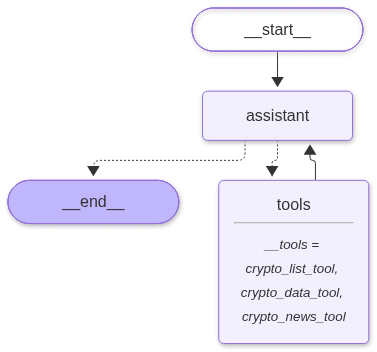

In [37]:
#visualizing the graph
from IPython.display import Image,display
display(Image(react_graph.get_graph(xray=True).draw_mermaid_png()))

In [38]:
#test agent
messages = [
    HumanMessage(
        content = "Look at the most recent news for both xrp and doge as well as the prices tell me is it worth investing and in which one "
    )
]

In [39]:
#invoke graph
out = react_graph.invoke({"messages":messages})

In [40]:
for m in out["messages"]:
    try:
        m.pretty_print()
    except Exception:
        print(m)

================================ Human Message =================================

Look at the most recent news for both xrp and doge as well as the prices tell me is it worth investing and in which one 
================================== Ai Message ==================================
Tool Calls:
  crypto_data_tool (fc_67202257-e1b9-46ee-8dd6-cbc32fa4acc6)
 Call ID: fc_67202257-e1b9-46ee-8dd6-cbc32fa4acc6
  Args:
    symbol: XRP
================================= Tool Message =================================
Name: crypto_data_tool

{
  "status": "success",
  "symbols": [
    {
      "symbol": "XRP",
      "last": "0.9479",
      "last_btc": "0.000015626955121014",
      "lowest": "0.9327",
      "highest": "0.9638",
      "date": "2026-11-26 18:01:06",
      "daily_change_percentage": "0.62632696390658",
      "source_exchange": "binance"
    }
  ]
}
================================== Ai Message ==================================
Tool Calls:
  crypto_data_tool (fc_7e4e2e53-6820-4973-8e51

In [41]:
#compile memory
memory =MemorySaver()
react_graph_memory = builder.compile(checkpointer=memory)

In [42]:
print("Crypto ReAct Agent -type 'exit' to quit.\n")

Crypto ReAct Agent -type 'exit' to quit.



In [43]:
#add thread_id
config = {"configurable":{"thread_id":"crypto-1thread-1"}}

In [44]:
while True:
    try:
        user_input = input("You:").strip()
    except(EOFError,keyboardInterrupt):
        print("\n Bye!")
        break

    if not user_input:
        continue
    if user_input.lower() in {"exit","quit"}:
        print("Bye!")
        break


    try:
        messages = [HumanMessage(content=user_input)]
        result = react_graph_memory.invoke({"messages":messages},config)

        last_ai = next((m for m in reversed(result["messages"]) if m.type =="ai") ,None)
        if last_ai:
            print(f"Agent: {last_ai.content}\n")
        else:
            print("Agent :[No reply]\n")
    
    except Exception as e:
        print(f"Error:{e}")

Agent: **Summary**  
- **XRP** is trading just under $1 (≈ $0.95) with a modest daily gain of **+0.58 %**.  
- **Dogecoin (DOGE)** is trading at **$0.0567** with a stronger daily gain of **+1.29 %**, but it has recently been pressured by a sharp price drop toward the $0.05 level.  

Both assets show short‑term upside, but the surrounding news points to very different risk profiles.

---

## 1. Current Market Data  *(source: `crypto_data_tool`)*  

| Asset | Last price (USD) | 24‑h % change | 24‑h Low / High | Exchange |
|-------|------------------|--------------|----------------|----------|
| **XRP** | **$0.9475** | **+0.58 %** | $0.9327 – $0.9638 | Binance |
| **DOGE**| **$0.0567** | **+1.29 %** | $0.05574 – $0.05724 | Binance |

---

## 2. Most Recent News (last 48 h)  *(source: `crypto_news_tool`)*  

### XRP  
- **“XRP slips below $1 as Ripple’s business wins fail to lift the token”** – Crypto Briefing (25 Nov) – Highlights a disconnect between Ripple’s corporate progress and token

In [ ]:
#adding config
#messages = [
    #HumanMessage(
      #  content = "Look at the most recent news for both xrp and doge as well as the prices tell me is it worth investing and in which one "
  #  )
#]
#invoke graph
#out = react_graph.invoke({"messages":messages},config)
#for m in out["messages"]:
    #try:
    #    m.pretty_print()
    #except Exception:
    #    print(m)

================================ Human Message =================================

Look at the most recent news for both xrp and doge as well as the prices tell me is it worth investing and in which one 
================================== Ai Message ==================================
Tool Calls:
  crypto_data_tool (fc_d028c36f-7647-4ff5-bc44-f64e36f46dae)
 Call ID: fc_d028c36f-7647-4ff5-bc44-f64e36f46dae
  Args:
    symbol: XRP
================================= Tool Message =================================
Name: crypto_data_tool

{
  "status": "success",
  "symbols": [
    {
      "symbol": "XRP",
      "last": "0.952",
      "last_btc": "0.000015627223739985",
      "lowest": "0.9327",
      "highest": "0.9638",
      "date": "2026-11-26 16:53:34",
      "daily_change_percentage": "1.0615711252654",
      "source_exchange": "binance"
    }
  ]
}
================================== Ai Message ==================================
Tool Calls:
  crypto_data_tool (fc_85d8bc08-d8d1-44a8-bab6-7

In [ ]:
#messages = [
 #   HumanMessage(content="Which one did you say was stronger again? And summarize their news in 3 bullets")
#]

#out= react_graph_memory.invoke({"messages":messages}, config)

In [ ]:
#for m in out["messages"]:
   # try:
    #    m.pretty_print()
    #except Exception:
      #  print(m)

================================ Human Message =================================

Which one did you say was stronger again? And summarize their news in 3 bullets
================================== Ai Message ==================================
Tool Calls:
  crypto_data_tool (fc_c0b65500-9637-43ea-90ca-4531b5a941f7)
 Call ID: fc_c0b65500-9637-43ea-90ca-4531b5a941f7
  Args:
    symbol: BTC
================================= Tool Message =================================
Name: crypto_data_tool

{
  "status": "success",
  "symbols": [
    {
      "symbol": "BTC",
      "last": "60856.85",
      "last_btc": "1",
      "lowest": "59942.55",
      "highest": "61469.3",
      "date": "2026-11-26 16:54:47",
      "daily_change_percentage": "0.9720095946625",
      "source_exchange": "binance"
    }
  ]
}
================================== Ai Message ==================================
Tool Calls:
  crypto_data_tool (fc_bf04d2f7-19de-4e9e-ad1b-eaacedda30f7)
 Call ID: fc_bf04d2f7-19de-4e9e-ad1b-eaac